In [5]:
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, make_scorer,
    ConfusionMatrixDisplay
)

SEED = 67
CV_SEED = 42


In [6]:
# pip install matplotlib

In [7]:
DATA_PATH = Path("../data/Telco-Customer-Churn.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH.resolve()}")

df = pd.read_csv(DATA_PATH)
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].astype(str).str.strip(), errors="coerce"
)

X = df.drop(columns=["Churn", "customerID"], errors="ignore")
y = df["Churn"].astype(str)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEED,
    stratify=y, shuffle=True
)

num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
cat_cols = ['gender', 'SeniorCitizen', 'Partner', 'Dependents',
        'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod']

print("Dataset:", df.shape)
print("Train rows:", len(X_train), "| Hold-out rows:", len(X_test))
print("Target labels:", sorted(y.unique()))


Dataset: (7043, 21)
Train rows: 5282 | Hold-out rows: 1761
Target labels: ['No', 'Yes']


In [8]:
preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), num_cols),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore")),
    ]), cat_cols),
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=CV_SEED)

# Explicitly define churn ("Yes") as the positive class.
recall_yes = make_scorer(recall_score, pos_label="Yes", zero_division=0)
precision_yes = make_scorer(precision_score, pos_label="Yes", zero_division=0)
f1_yes = make_scorer(f1_score, pos_label="Yes", zero_division=0)
scoring = {
    "recall_yes": recall_yes,
    "precision_yes": precision_yes,
    "f1_yes": f1_yes,
    "accuracy": "accuracy",
    "roc_auc": "roc_auc",
}


In [ ]:
estimators = {
    "Decision Tree": DecisionTreeClassifier(random_state=SEED),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, random_state=SEED, n_jobs=-1
    ),
    "SVM": SVC(
        kernel="rbf", C=1.0, probability=True, random_state=SEED
    ),
}

pipelines = {
    name: Pipeline([("preprocessor", preprocessor), ("model", estimator)])
    for name, estimator in estimators.items()
}

cv_rows = []
for name, pipe in pipelines.items():
    cv_out = cross_validate(
        pipe, X_train, y_train, cv=cv, scoring=scoring,
        n_jobs=1, return_train_score=False
    )
    row = {"Model": name}
    for metric in scoring:
        vals = cv_out[f"test_{metric}"]
        row[f"CV {metric}"] = vals.mean()
        row[f"CV {metric} std"] = vals.std()
    cv_rows.append(row)

cv_results = pd.DataFrame(cv_rows).sort_values(
    "CV recall_yes", ascending=False
).reset_index(drop=True)
display(cv_results.round(4))


c:\Users\sohom\Workspace\RetailMindAI\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


In [ ]:
fitted_models = {}
test_rows = []

for name, pipe in pipelines.items():
    pipe.fit(X_train, y_train)
    fitted_models[name] = pipe
    pred = pipe.predict(X_test)

    classes = list(pipe.named_steps["model"].classes_)
    yes_index = classes.index("Yes")
    probability_yes = pipe.predict_proba(X_test)[:, yes_index]

    test_rows.append({
        "Model": name,
        "Hold-out Recall (Yes)": recall_score(y_test, pred, pos_label="Yes", zero_division=0),
        "Hold-out Precision (Yes)": precision_score(y_test, pred, pos_label="Yes", zero_division=0),
        "Hold-out F1 (Yes)": f1_score(y_test, pred, pos_label="Yes", zero_division=0),
        "Hold-out Accuracy": accuracy_score(y_test, pred),
        "Hold-out ROC-AUC": roc_auc_score((y_test == "Yes").astype(int), probability_yes),
    })

test_results = pd.DataFrame(test_rows)
comparison = cv_results[["Model", "CV recall_yes", "CV recall_yes std"]].merge(
    test_results, on="Model"
).sort_values("CV recall_yes", ascending=False).reset_index(drop=True)

display(comparison.round(4))


c:\Users\sohom\Workspace\RetailMindAI\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,Model,CV recall_yes,CV recall_yes std,Hold-out Recall (Yes),Hold-out Precision (Yes),Hold-out F1 (Yes),Hold-out Accuracy,Hold-out ROC-AUC
0,SVM,0.5064,0.0161,0.4989,0.6436,0.5621,0.7939,0.7973
1,Decision Tree,0.4993,0.0493,0.5161,0.4820,0.4984,0.7246,0.6581
2,Random Forest,0.4857,0.0256,0.4839,0.6209,0.5439,0.7848,0.8087


Champion: SVM
Mean CV churn recall: 0.5064
Hold-out churn recall: 0.4989
Hold-out churn precision: 0.6436
Hold-out churn F1: 0.5621

Classification report on the shared hold-out set:
              precision    recall  f1-score   support

          No       0.83      0.90      0.87      1294
         Yes       0.64      0.50      0.56       467

    accuracy                           0.79      1761
   macro avg       0.74      0.70      0.71      1761
weighted avg       0.78      0.79      0.78      1761



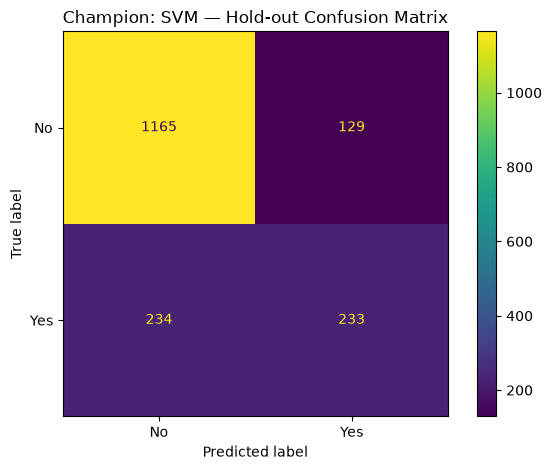

In [ ]:
# Selection is based on training-fold CV recall for "Yes", not the hold-out score.
champion_name = cv_results.iloc[0]["Model"]
champion = fitted_models[champion_name]
champion_test = test_results.loc[test_results["Model"] == champion_name].iloc[0]

print("Champion:", champion_name)
print(f"Mean CV churn recall: {champion_test['Model'] and cv_results.iloc[0]['CV recall_yes']:.4f}")
print(f"Hold-out churn recall: {champion_test['Hold-out Recall (Yes)']:.4f}")
print(f"Hold-out churn precision: {champion_test['Hold-out Precision (Yes)']:.4f}")
print(f"Hold-out churn F1: {champion_test['Hold-out F1 (Yes)']:.4f}")
print("\nClassification report on the shared hold-out set:")
print(classification_report(y_test, champion.predict(X_test), labels=["No", "Yes"], zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test, champion.predict(X_test), labels=["No", "Yes"],
    display_labels=["No", "Yes"], values_format="d"
)
plt.title(f"Champion: {champion_name} — Hold-out Confusion Matrix")
plt.tight_layout()
plt.show()
